In [ ]:
%pip install pandas numpy matplotlib seaborn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("zomato.zip")

display(df.head())

print("Dataset size:", df.shape)
print("Columns:", df.columns.tolist())

,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari


Dataset size: (51717, 17)
Columns: ['url', 'address', 'name', 'online_order', 'book_table', 'rate', 'votes', 'phone', 'location', 'rest_type', 'dish_liked', 'cuisines', 'approx_cost(for two people)', 'reviews_list', 'menu_item', 'listed_in(type)', 'listed_in(city)']


In [3]:


print("Missing values in each column:")
print(df.isnull().sum())


print("\nDuplicate rows:", df.duplicated().sum())


display(df.describe(include="all").T)


Missing values in each column:
url                                0
address                            0
name                               0
online_order                       0
book_table                         0
rate                            7775
votes                              0
phone                           1208
location                          21
rest_type                        227
dish_liked                     28078
cuisines                          45
approx_cost(for two people)      346
reviews_list                       0
menu_item                          0
listed_in(type)                    0
listed_in(city)                    0
dtype: int64

Duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
url,51717,51717,https://www.zomato.com/bangalore/jalsa-banasha...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
address,51717,11495,Delivery Only,128,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,51717,8792,Cafe Coffee Day,96,NaN,NaN,NaN,NaN,NaN,NaN,NaN
online_order,51717,2,Yes,30444,NaN,NaN,NaN,NaN,NaN,NaN,NaN
book_table,51717,2,No,45268,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rate,43942,64,NEW,2208,NaN,NaN,NaN,NaN,NaN,NaN,NaN
votes,51717.0,NaN,NaN,NaN,283.697527,803.838853,0.0,7.0,41.0,198.0,16832.0
phone,50509,14926,080 43334321,216,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location,51696,93,BTM,5124,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rest_type,51490,93,Quick Bites,19132,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:

# Standardize column names
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

# Convert common rating columns to numeric
rating_col = next(
    (c for c in ["rate", "rating", "aggregate_rating"]
     if c in df.columns), None
)

if rating_col:
    df[rating_col] = pd.to_numeric(
        df[rating_col].astype(str)
        .str.extract(r"(\d+(?:\.\d+)?)")[0],
        errors="coerce"
    )
    df.loc[~df[rating_col].between(0, 5), rating_col] = np.nan

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

print("Rows after cleaning:", len(df))
print("Columns after cleaning:", len(df.columns))


Rows after cleaning: 51717
Columns after cleaning: 17


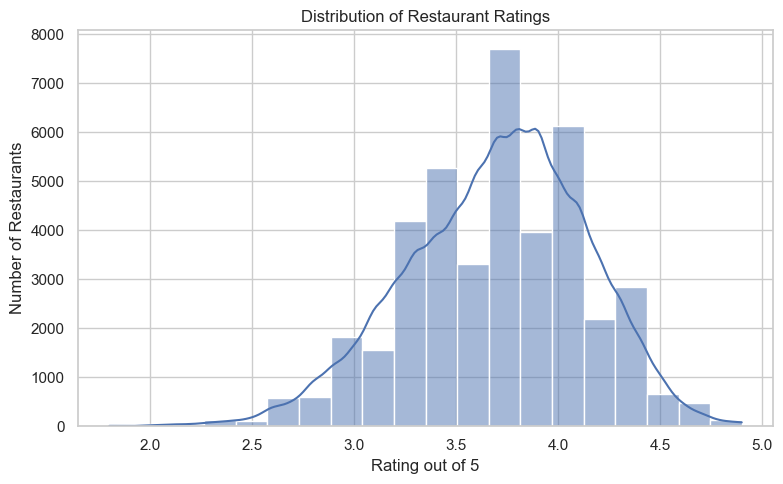

In [5]:

if rating_col:
    plt.figure(figsize=(8, 5))
    sns.histplot(df[rating_col].dropna(), bins=20, kde=True)
    plt.title("Distribution of Restaurant Ratings")
    plt.xlabel("Rating out of 5")
    plt.ylabel("Number of Restaurants")
    plt.tight_layout()
    plt.show()
else:
    print("Rating column not found.")


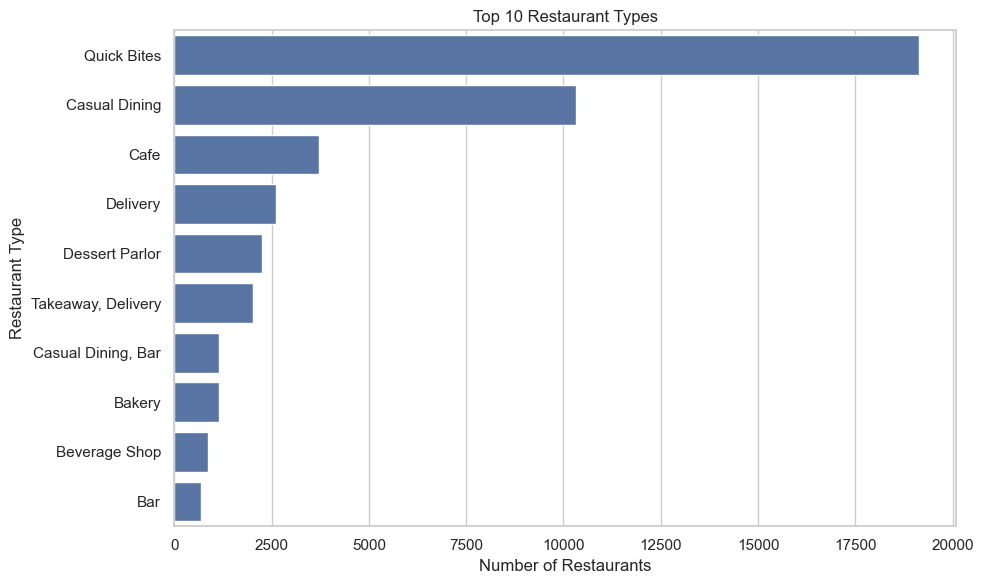

In [6]:

type_col = next(
    (c for c in ["rest_type", "restaurant_type"]
     if c in df.columns), None
)

if type_col:
    top_types = df[type_col].dropna().value_counts().head(10)

    plt.figure(figsize=(10, 6))
    sns.barplot(x=top_types.values, y=top_types.index)
    plt.title("Top 10 Restaurant Types")
    plt.xlabel("Number of Restaurants")
    plt.ylabel("Restaurant Type")
    plt.tight_layout()
    plt.show()
else:
    print("Restaurant type column not found.")


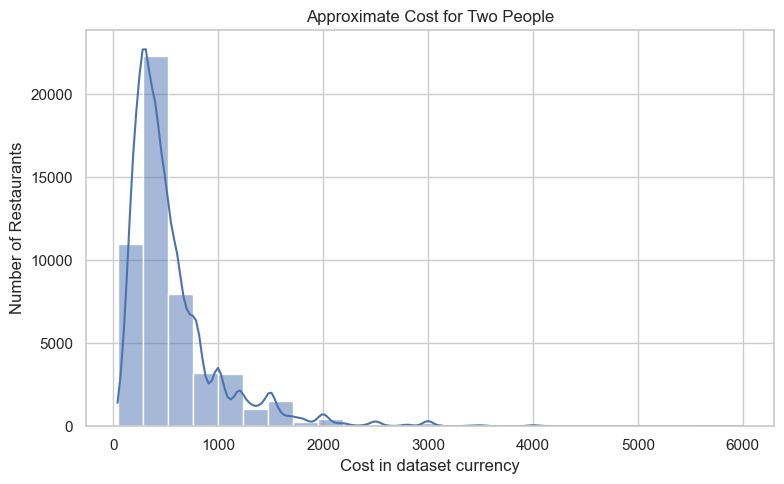

In [7]:

cost_col = next(
    (c for c in ["approx_cost_for_two_people",
                 "approx_cost", "cost_for_two",
                 "average_cost_for_two"]
     if c in df.columns), None
)

if cost_col:
    df[cost_col] = pd.to_numeric(
        df[cost_col].astype(str)
        .str.replace(",", "", regex=False)
        .str.replace(r"[^0-9.]", "", regex=True),
        errors="coerce"
    )

    plt.figure(figsize=(8, 5))
    sns.histplot(df[cost_col].dropna(), bins=25, kde=True)
    plt.title("Approximate Cost for Two People")
    plt.xlabel("Cost in dataset currency")
    plt.ylabel("Number of Restaurants")
    plt.tight_layout()
    plt.show()
else:
    print("Cost column not found.")


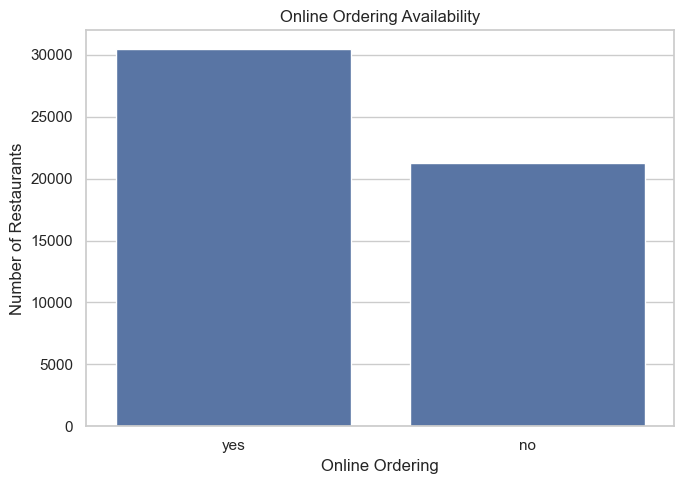

In [8]:

online_col = next(
    (c for c in ["online_order", "has_online_delivery"]
     if c in df.columns), None
)

if online_col:
    order_counts = (
        df[online_col].astype("string")
        .str.strip().str.lower().value_counts()
    )

    plt.figure(figsize=(7, 5))
    sns.barplot(x=order_counts.index, y=order_counts.values)
    plt.title("Online Ordering Availability")
    plt.xlabel("Online Ordering")
    plt.ylabel("Number of Restaurants")
    plt.tight_layout()
    plt.show()
else:
    print("Online-ordering column not found.")


In [9]:

print("ZOMATO DATA ANALYSIS — FINDINGS")
print("-" * 35)

print("Total records:", len(df))

if rating_col:
    print("Average rating:", round(df[rating_col].mean(), 2))

if type_col:
    print("Most common restaurant type:",
          df[type_col].value_counts().idxmax())

if cost_col:
    print("Median cost for two:", df[cost_col].median())

if online_col:
    print("\nOnline-ordering counts:")
    print(df[online_col].value_counts(dropna=False))


ZOMATO DATA ANALYSIS — FINDINGS
-----------------------------------
Total records: 51717
Average rating: 3.7
Most common restaurant type: Quick Bites
Median cost for two: 400.0

Online-ordering counts:
online_order
Yes    30444
No     21273
Name: count, dtype: int64


In [10]:

df.to_csv("zomato_cleaned.csv", index=False)
print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [11]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load your cleaned dataset
df = pd.read_csv("zomato_cleaned.csv")

# Find the rating column
print(df.columns.tolist())


['url', 'address', 'name', 'online_order', 'book_table', 'rate', 'votes', 'phone', 'location', 'rest_type', 'dish_liked', 'cuisines', 'approx_cost_for_two_people', 'reviews_list', 'menu_item', 'listed_in_type', 'listed_in_city']


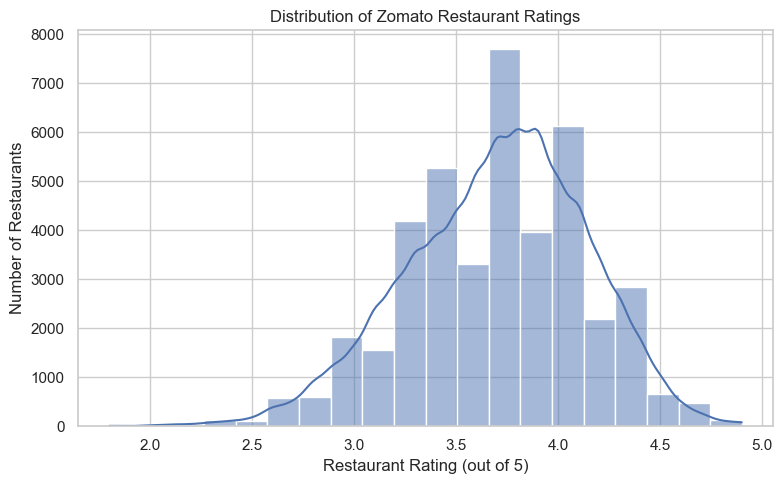

Chart 1 saved successfully!


In [12]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned dataset
df = pd.read_csv("zomato_cleaned.csv")

# Convert ratings into numbers
df["rate"] = pd.to_numeric(df["rate"], errors="coerce")

# Create chart
plt.figure(figsize=(8, 5))
sns.histplot(df["rate"].dropna(), bins=20, kde=True)

plt.title("Distribution of Zomato Restaurant Ratings")
plt.xlabel("Restaurant Rating (out of 5)")
plt.ylabel("Number of Restaurants")

plt.tight_layout()
plt.savefig("chart1_ratings.png", dpi=150)
plt.show()

print("Chart 1 saved successfully!")


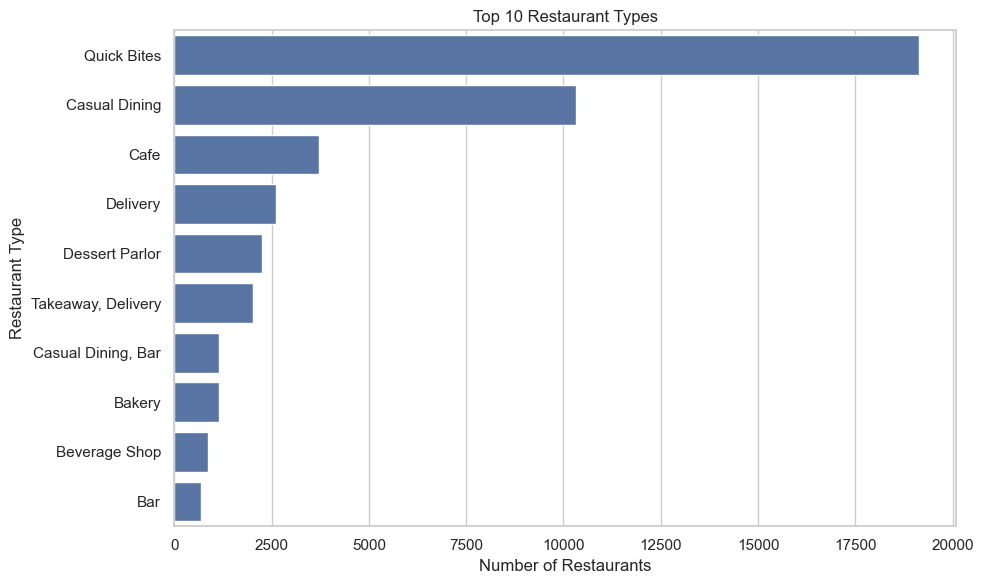

Chart 2 saved successfully!


In [13]:

top_types = df["rest_type"].dropna().value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_types.values, y=top_types.index)

plt.title("Top 10 Restaurant Types")
plt.xlabel("Number of Restaurants")
plt.ylabel("Restaurant Type")

plt.tight_layout()
plt.savefig("chart2_restaurant_types.png", dpi=150)
plt.show()

print("Chart 2 saved successfully!")


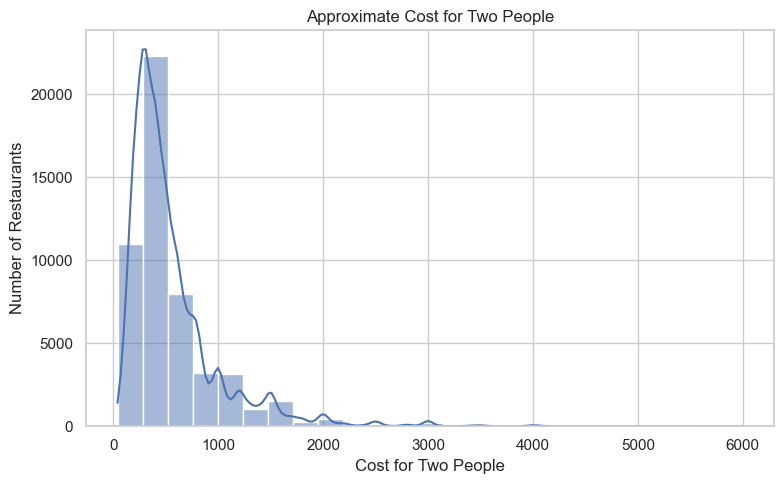

Chart 3 saved successfully!


In [14]:

# Chart 3: Cost analysis

df["approx_cost_for_two_people"] = pd.to_numeric(
    df["approx_cost_for_two_people"]
    .astype(str)
    .str.replace(",", "", regex=False),
    errors="coerce"
)

plt.figure(figsize=(8, 5))

sns.histplot(
    df["approx_cost_for_two_people"].dropna(),
    bins=25,
    kde=True
)

plt.title("Approximate Cost for Two People")
plt.xlabel("Cost for Two People")
plt.ylabel("Number of Restaurants")

plt.tight_layout()
plt.savefig("chart3_cost.png", dpi=150)
plt.show()

print("Chart 3 saved successfully!")


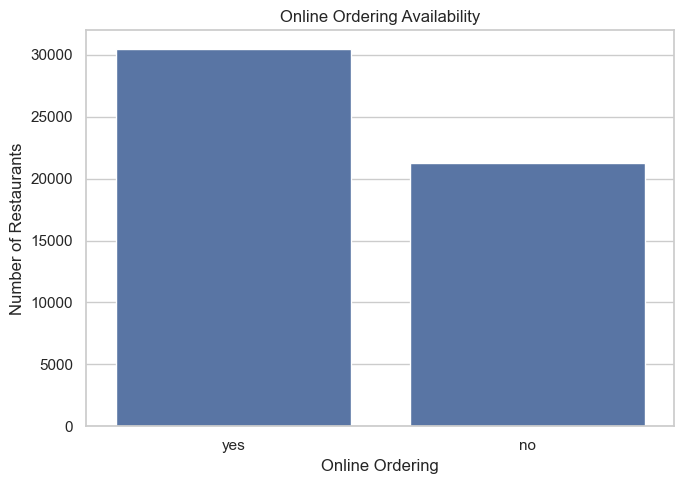

Chart 4 saved successfully!


In [15]:

# Chart 4: Online ordering analysis

order_counts = (
    df["online_order"]
    .astype("string")
    .str.strip()
    .str.lower()
    .value_counts()
)

plt.figure(figsize=(7, 5))

sns.barplot(
    x=order_counts.index,
    y=order_counts.values
)

plt.title("Online Ordering Availability")
plt.xlabel("Online Ordering")
plt.ylabel("Number of Restaurants")

plt.tight_layout()
plt.savefig("chart4_online_order.png", dpi=150)
plt.show()

print("Chart 4 saved successfully!")


In [16]:

# 1. Average restaurant rating
print("Average Rating:", round(df["rate"].mean(), 2))

# 2. Top 10 restaurant types
print("\nTop 10 Restaurant Types:")
print(df["rest_type"].value_counts().head(10))

# 3. Average cost for two people
df["approx_cost_for_two_people"] = pd.to_numeric(
    df["approx_cost_for_two_people"].astype(str).str.replace(",", ""),
    errors="coerce"
)
print("\nAverage Cost for Two:",
      round(df["approx_cost_for_two_people"].mean(), 2))

# 4. Online ordering availability
print("\nOnline Ordering:")
print(df["online_order"].value_counts())

# 5. Table booking availability
print("\nTable Booking:")
print(df["book_table"].value_counts())

# 6. Top 10 restaurant locations
print("\nTop 10 Locations:")
print(df["location"].value_counts().head(10))


Average Rating: 3.7

Top 10 Restaurant Types:
rest_type
Quick Bites           19132
Casual Dining         10330
Cafe                   3732
Delivery               2604
Dessert Parlor         2263
Takeaway, Delivery     2037
Casual Dining, Bar     1154
Bakery                 1141
Beverage Shop           867
Bar                     697
Name: count, dtype: int64

Average Cost for Two: 555.43

Online Ordering:
online_order
Yes    30444
No     21273
Name: count, dtype: int64

Table Booking:
book_table
No     45268
Yes     6449
Name: count, dtype: int64

Top 10 Locations:
location
BTM                      5124
HSR                      2523
Koramangala 5th Block    2504
JP Nagar                 2235
Whitefield               2144
Indiranagar              2083
Jayanagar                1926
Marathahalli             1846
Bannerghatta Road        1630
Bellandur                1286
Name: count, dtype: int64



# Zomato Dataset Analysis

## Project Overview
This project analyzes Zomato restaurant data using Python.

## Key Findings
- Average rating: 3.7
- Average cost for two: ₹555.43
- Most common restaurant type: Quick Bites
- Top restaurant location: BTM
- Online ordering is available in 30,444 records.

## Conclusion
The analysis helps us understand restaurant ratings, costs, popular restaurant types, and service availability.
      

In [17]:

readme_content = """# Zomato Dataset Analysis

## Internship
Alfido Tech Internship - Task 1

## Project Overview
This project analyzes Zomato restaurant data to understand restaurant ratings,
restaurant types, approximate costs, online ordering, table booking, and locations.

## Tools Used
- Python
- Pandas
- Matplotlib
- Jupyter Notebook

## Key Findings
- Average restaurant rating: 3.7
- Average cost for two people: Rs. 555.43
- Most common restaurant type: Quick Bites
- Top restaurant location: BTM
- Records with online ordering: 30,444
- Records with table booking: 6,449

## Visualizations
1. Restaurant ratings distribution
2. Top 10 restaurant types
3. Approximate cost for two people
4. Online ordering availability

## Conclusion
The dataset analysis shows that Quick Bites is the most common restaurant
type in the data. Online ordering is more common than table booking.

## Author
Student - Information Technology
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")



README.md created successfully!


In [18]:

import os
print(os.path.abspath("README.md"))
print(os.path.exists("README.md"))


C:\Users\HP\shubham\README.md
True


In [19]:

import os

files = [
    "Zomato_Dataset_Analysis.ipynb",
    "zomato_cleaned.csv",
    "README.md",
    "chart1_ratings.png",
    "chart2_restaurant_types.png",
    "chart3_cost.png",
    "chart4_online_order.png"
]

for file in files:
    if os.path.exists(file):
        size_mb = os.path.getsize(file) / (1024 * 1024)
        print(f"{file}: {size_mb:.2f} MB")
    else:
        print(f"{file}: Not found in this folder")


Zomato_Dataset_Analysis.ipynb: 0.37 MB
zomato_cleaned.csv: 547.45 MB
README.md: 0.00 MB
chart1_ratings.png: 0.07 MB
chart2_restaurant_types.png: 0.06 MB
chart3_cost.png: 0.05 MB
chart4_online_order.png: 0.04 MB
